In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import logging
import random
from copy import deepcopy
import re
from sklearn.metrics import mean_squared_error

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import torch
import numpy as np
from dotenv import load_dotenv
from natsort import natsorted

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
runs_to_download = []

# Cellbox and Phoenix
runs_to_download.extend(mlflow.search_runs(
      experiment_ids=['12'], output_format='list'))

# MLP
runs_to_download.extend(mlflow.search_runs(
      filter_string=f"attributes.status = 'FINISHED' and params.model_class = 'HybridModel' and tags.mlflow.parentRunId ='f02bf732b2ba4817b254bd5174f1549b'",
            experiment_ids=['6'], output_format='list'))
print(len(runs_to_download))

15


In [8]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-06-18 16:50:25,243 - INFO - Downloading artifacts for run ed725481242d436dbe984ea751b46904
2026-06-18 16:50:26,968 - INFO - Downloading artifacts for run 31e3c61a21554f99a795087274e7e6b1
2026-06-18 16:50:28,663 - INFO - Downloading artifacts for run 9e8c44262dc946e7ae33aa7e56986542
2026-06-18 16:50:30,311 - INFO - Downloading artifacts for run a61566c5d1684bbbaf3e04591ea4b3bd
2026-06-18 16:50:31,973 - INFO - Downloading artifacts for run 588de7f12d7c4520bc65623090d89b0c
2026-06-18 16:50:33,701 - INFO - Downloading artifacts for run e760499314514087943fea5dfaeba9c1
2026-06-18 16:50:35,379 - INFO - Downloading artifacts for run b8bdd7b101684900b3c02a369455e1e3
2026-06-18 16:50:37,081 - INFO - Downloading artifacts for run d24e07a0a5384ea2bcee1f7e37b1bfc7
2026-06-18 16:50:38,790 - INFO - Downloading artifacts for run 4b8ca177b0e44ea9a491912f8ce63614
2026-06-18 16:50:40,487 - INFO - Downloading artifacts for run add7434d587c47b0b65eb42a18ee678b
2026-06-18 16:50:42,181 - INFO - Downloa

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.000000,0.000000,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.678575,0.678575,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.062423,0.062423,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.720982,0.720982,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.146307,0.146307,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b


In [ ]:
raw_predictions_df.shape

In [10]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    # Load model and get name of ML part
    run = mlflow.get_run(run_id)
    if 'nr_layers' in run.data.params:
        ml_method = 'MLP'
    elif 'hidden_size' in run.data.params:
        ml_method = 'Phoenix'
    else:
        ml_method = 'CellBox'
    model_name_records.append({
        'run_id': run_id,
        'model_name': f"{run.data.tags['mlflow.runName']}: {ml_method}",
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)
model_name_df['model_name'].value_counts()

model_name
HybridModel: CellBox    5
HybridModel: Phoenix    5
HybridModel: MLP        5
Name: count, dtype: int64

In [11]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes
0,Node_0,0.0,0.000000,0.000000,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
1,Node_1,0.0,0.678575,0.678575,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
2,Node_2,0.0,0.062423,0.062423,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
3,Node_3,0.0,0.720982,0.720982,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
4,Node_4,0.0,0.146307,0.146307,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."


In [12]:
records = []
nr_genes_list = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)

    run = mlflow.get_run(run_id)
    nr_genes_list.append({
        'parent_run_id': run_id,
        'nr_genes': run.data.params['nr_genes'],
    })
long_form_simulation = pd.concat(records, ignore_index=True)
nr_genes_df = pd.DataFrame(nr_genes_list)
nr_genes_df.head()

2026-06-18 16:52:18,743 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 16:52:18,749 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 16:52:18,753 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 16:52:18,768 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 16:52:18,783 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 16:52:18,797 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 16:52:18,813 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-18 16:52:18,853 - WARNING - Connection p

,parent_run_id,nr_genes
0,f02bf732b2ba4817b254bd5174f1549b,50


In [13]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

outcome.head()

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,modelled_genes,ground_truth_from_simulation,run_id_from_simulation,nr_genes
0,Node_0,0.0,0.000000,0.000000,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.022225,f02bf732b2ba4817b254bd5174f1549b,50
1,Node_1,0.0,0.678575,0.678575,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.557310,f02bf732b2ba4817b254bd5174f1549b,50
2,Node_2,0.0,0.062423,0.062423,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.080057,f02bf732b2ba4817b254bd5174f1549b,50
3,Node_3,0.0,0.720982,0.720982,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.702816,f02bf732b2ba4817b254bd5174f1549b,50
4,Node_4,0.0,0.146307,0.146307,KO: Node_26. Env: None,ed725481242d436dbe984ea751b46904,f02bf732b2ba4817b254bd5174f1549b,HybridModel: CellBox,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.057769,f02bf732b2ba4817b254bd5174f1549b,50


In [14]:
outcome.model_name.value_counts()

model_name
HybridModel: CellBox    525000
HybridModel: Phoenix    525000
HybridModel: MLP        525000
Name: count, dtype: int64

In [15]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'nr_genes']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

In [16]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [ ]:
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
        lambda row: lookup[(
            row['condition'],
            row['modelled_genes'] if row['modelled_genes'] is not None else None
        )],
    axis=1
)
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [ ]:
double_ko_df.model_name.value_counts()

In [17]:
groupby_list = [
    'model_name',
    'modelled_genes',
    'nr_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    # 'parameters_set_to_zero'
]
mse_df = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

In [23]:
mse_df['model_name'].unique()

array(['HybridModel: CellBox', 'HybridModel: MLP', 'HybridModel: Phoenix'],
      dtype=object)

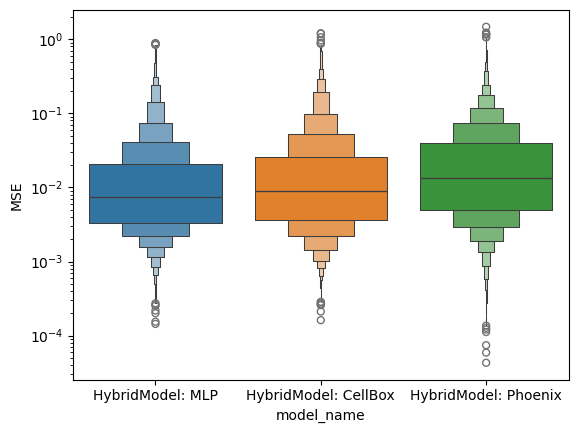

In [31]:
g = sns.boxenplot(data=mse_df, hue='model_name', x='model_name', y='MSE', log_scale=True, 
              order=['HybridModel: MLP', 'HybridModel: CellBox', 'HybridModel: Phoenix'],
              hue_order=['HybridModel: MLP', 'HybridModel: CellBox', 'HybridModel: Phoenix'])
for artist in g.get_children():
    artist.set_rasterized(True)

# plt.tight_layout()
# for text in g._margin_titles_texts:
#     text.set_visible(False)

g.figure.savefig("hybrid_other_architectures.pdf", dpi=600, bbox_inches='tight')